# STA6130 Week 8 Group Assignment: Forecasting as Regression and Feature Engineering
**Dataset:** Store Item Demand Forecasting Challenge (Kaggle), daily unit sales, 1 Jan 2013 to 31 Dec 2017  
**Competition:** https://www.kaggle.com/c/demand-forecasting-kernels-only  (data: `train.csv` with columns `date, store, item, sales`)  

**Mapping to the assignment:** sections 1 to 10 below follow the ten required report items, so each output can be pasted straight into the matching part of the report.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

## 1. Describe the forecasting problem

In [2]:
def find_train_csv():
    # 1) a copy next to the notebook, 2) the Kaggle notebook input folder, 3) kagglehub download
    for path in ["train.csv", "/kaggle/input/demand-forecasting-kernels-only/train.csv"]:
        if os.path.exists(path):
            return path
    try:
        import kagglehub
        folder = kagglehub.competition_download("demand-forecasting-kernels-only")
        hits = glob.glob(os.path.join(folder, "**", "train.csv"), recursive=True)
        if hits:
            return hits[0]
    except Exception as e:
        print("kagglehub download failed:", e)
    raise FileNotFoundError(
        "train.csv not found. Join the competition, download the data from"
        )

raw = pd.read_csv(find_train_csv(), parse_dates=["date"])
print("Full file:", raw.shape, "| stores:", raw["store"].nunique(), "| items:", raw["item"].nunique())
print("Period:", raw["date"].min().date(), "to", raw["date"].max().date())

# One store-item series (local model); change these IDs to select a different series.
STORE = 1
ITEM = 1
s = (raw[(raw["store"] == STORE) & (raw["item"] == ITEM)]
     .sort_values("date").set_index("date")["sales"].astype(float).asfreq("D"))
assert s.isna().sum() == 0, "missing days found: impute carefully (never with future values)"
print(f"\nSeries: store {STORE}, item {ITEM}: {len(s)} daily observations, {s.index.min().date()} to {s.index.max().date()}")
print(s.describe().round(2))

Full file: (913000, 4) | stores: 10 | items: 50
Period: 2013-01-01 to 2017-12-31

Series: store 1, item 1: 1826 daily observations, 2013-01-01 to 2017-12-31
count    1826.00
mean       19.97
std         6.74
min         4.00
25%        15.00
50%        19.00
75%        24.00
max        50.00
Name: sales, dtype: float64


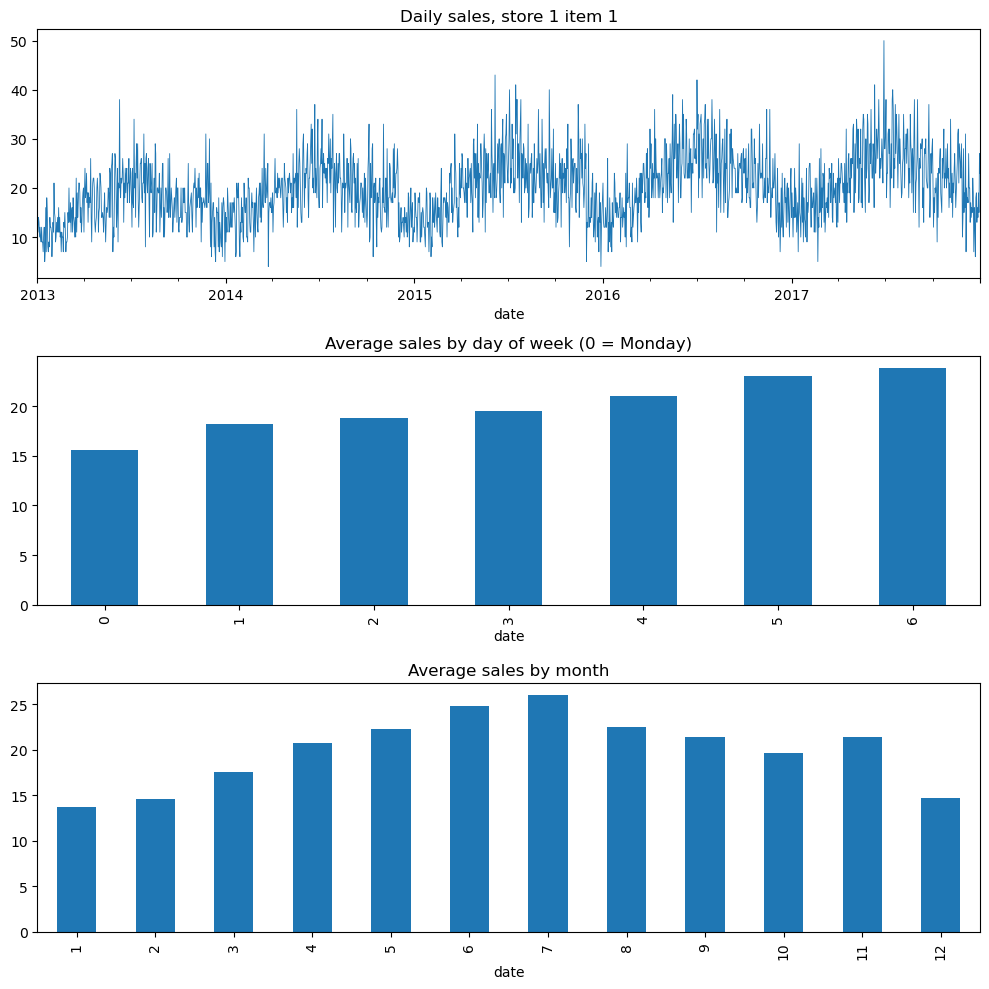

autocorrelation at lag   1: 0.448
autocorrelation at lag   2: 0.366
autocorrelation at lag   3: 0.345
autocorrelation at lag   7: 0.571
autocorrelation at lag  14: 0.553
autocorrelation at lag  21: 0.515
autocorrelation at lag  28: 0.501
autocorrelation at lag 364: 0.564


In [3]:
# Exploratory plots: level/trend, weekly pattern, yearly pattern
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
s.plot(ax=axes[0], lw=0.6, title=f"Daily sales, store {STORE} item {ITEM}")
s.groupby(s.index.dayofweek).mean().plot(kind="bar", ax=axes[1], title="Average sales by day of week (0 = Monday)")
s.groupby(s.index.month).mean().plot(kind="bar", ax=axes[2], title="Average sales by month")
plt.tight_layout(); plt.show()

# Autocorrelation at candidate lags (justifies which lags to engineer)
for k in [1, 2, 3, 7, 14, 21, 28, 364]:
    print(f"autocorrelation at lag {k:3d}: {s.autocorr(lag=k):.3f}")

## 2 and 3. Convert the series into a supervised regression table and create features

Every row is one **day to be predicted** (its `target` is that day's sales). All inputs are built only from information known `H` days earlier, so row *T* never sees the sales of day *T*.

| Category | Features | Why they help |
|---|---|---|
| Lag | `lag_k` for k = 1, 2, 3, 7, 14, 28 (only k >= H) | Persistence and weekly memory |
| Rolling (shifted) | mean, std, min, max over 7 and 28 days | Recent level, volatility and range |
| EWMA (shifted) | exponentially weighted average | Recent level with more weight on newer days |
| Calendar | day of week, weekend flag, month, quarter, week of year | Weekly and annual patterns |
| Trend | `time_index` | Long-run growth |
| Seasonal (Fourier) | sin/cos terms with periods 7 and 365.25 | Smooth weekly and yearly cycles |

In [4]:
def build_features(y: pd.Series, H: int = 1) -> pd.DataFrame:
    df = pd.DataFrame({"target": y})

    # --- Lag features (k days before the day being predicted; must satisfy k >= H to be known in advance)
    for k in [1, 2, 3, 7, 14, 28]:
        if k >= H:
            df[f"lag_{k}"] = y.shift(k)

    # --- Rolling features: SHIFT FIRST so the window ends at the last known day
    known = y.shift(H)
    for w in [7, 28]:
        r = known.rolling(w)
        df[f"roll_mean_{w}"] = r.mean()
        df[f"roll_std_{w}"]  = r.std()
        df[f"roll_min_{w}"]  = r.min()
        df[f"roll_max_{w}"]  = r.max()
    df["ewma_alpha03"] = known.ewm(alpha=0.3, adjust=False).mean()

    # --- Calendar features (known in advance for any future date)
    idx = df.index
    df["day_of_week"]  = idx.dayofweek
    df["is_weekend"]   = (idx.dayofweek >= 5).astype(int)
    df["month"]        = idx.month
    df["quarter"]      = idx.quarter
    df["week_of_year"] = idx.isocalendar().week.astype(int).values

    # --- Trend feature
    df["time_index"] = np.arange(len(df))

    # --- Fourier (seasonal) features
    t = df["time_index"].values
    for k in (1, 2):
        df[f"sin_week_{k}"] = np.sin(2 * np.pi * k * t / 7)
        df[f"cos_week_{k}"] = np.cos(2 * np.pi * k * t / 7)
    for k in (1, 2, 3):
        df[f"sin_year_{k}"] = np.sin(2 * np.pi * k * t / 365.25)
        df[f"cos_year_{k}"] = np.cos(2 * np.pi * k * t / 365.25)
    return df

H = 1  # one-day-ahead forecast horizon
features_all = build_features(s, H)
model_df = features_all.dropna().copy()          # rows without full lag/rolling history are dropped
feature_cols = [c for c in model_df.columns if c != "target"]
print(f"Rows before dropping: {len(features_all)} | after: {len(model_df)} | features: {len(feature_cols)}")
model_df[["target"] + feature_cols].head(8).round(2)

Rows before dropping: 1826 | after: 1798 | features: 31


,target,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_std_7,roll_min_7,...,sin_week_1,cos_week_1,sin_week_2,cos_week_2,sin_year_1,cos_year_1,sin_year_2,cos_year_2,sin_year_3,cos_year_3
date,,,,,,,,,,,,,,,,,,,,,
2013-01-29,6.0,11.0,12.0,12.0,7.0,5.0,13.0,10.43,2.51,7.0,...,-0.00,1.00,-0.00,1.00,0.46,0.89,0.82,0.57,0.99,0.13
2013-01-30,9.0,6.0,11.0,12.0,9.0,7.0,11.0,10.29,2.75,6.0,...,0.78,0.62,0.97,-0.22,0.48,0.88,0.84,0.54,1.00,0.07
2013-01-31,13.0,9.0,6.0,11.0,8.0,16.0,14.0,10.29,2.75,6.0,...,0.97,-0.22,-0.43,-0.90,0.49,0.87,0.86,0.51,1.00,0.02
2013-02-01,11.0,13.0,9.0,6.0,14.0,7.0,13.0,11.00,2.71,6.0,...,0.43,-0.90,-0.78,0.62,0.51,0.86,0.88,0.48,1.00,-0.03
2013-02-02,21.0,11.0,13.0,9.0,12.0,18.0,10.0,10.57,2.37,6.0,...,-0.43,-0.90,0.78,0.62,0.52,0.85,0.89,0.45,1.00,-0.08
2013-02-03,15.0,21.0,11.0,13.0,12.0,15.0,12.0,11.86,4.63,6.0,...,-0.97,-0.22,0.43,-0.90,0.54,0.84,0.91,0.42,0.99,-0.13
2013-02-04,14.0,15.0,21.0,11.0,11.0,8.0,10.0,12.29,4.79,6.0,...,-0.78,0.62,-0.97,-0.22,0.55,0.83,0.92,0.39,0.98,-0.18
2013-02-05,9.0,14.0,15.0,21.0,6.0,7.0,9.0,12.71,4.79,6.0,...,-0.00,1.00,-0.00,1.00,0.57,0.82,0.93,0.36,0.97,-0.23
